# 03 · Do telemetry and jobs share one clock?

**Paper:** Section III-D (*Telemetry and jobs synchronicity*).

A fixed window after the job's start means something only if the telemetry timestamps and the
job times are on the same clock. Three checks:

1. **Job tables.** The job times in PM100 and in ExaData's own job table must agree.
2. **Power step.** On a node that was idle for hours, node power must jump exactly when a job
   starts.
3. **PM100 power traces.** PM100 also ships a per-job power trace (`node_power_consumption`,
   one sample every 20 s). Compared with ExaData's node power, it only lines up when shifted by
   +2 h, so we do not use it.

Checks 2 and 3 use June 2020, which lies entirely in European summer time (UTC+2).

In [1]:
import sys
sys.path.insert(0, "..")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.compute as pc
import pyarrow.parquet as pq

from tcc.config import M100, MONTHS, PM100_JOBS, SEED
from tcc.claims import claim, save_claims

## 1. PM100 job table against ExaData's job table

In [2]:
cols = ["job_id", "submit_time", "start_time", "end_time"]
exa = pd.concat([pd.read_parquet(p, columns=cols) for m in MONTHS
                 for p in (M100 / f"year_month={m}" / "plugin=job_table" / "metric=job_info_marconi100").glob("*.parquet")])
exa = exa.drop_duplicates("job_id")
pm = pd.read_parquet(PM100_JOBS, columns=cols)
both = pm.merge(exa, on="job_id", suffixes=("_pm100", "_exadata"))
for c in ("submit_time", "start_time", "end_time"):
    diff = (pd.to_datetime(both[f"{c}_exadata"], utc=True) - both[f"{c}_pm100"]).dt.total_seconds().abs()
    print(f"{c:12s} largest difference: {diff.max():.0f} s")
    assert diff.max() == 0
print(f"PM100 jobs found in ExaData's job table: {len(both):,} of {len(pm):,}")
claim("PM100 jobs whose times agree with ExaData to the second", len(both), "231,238")

submit_time  largest difference: 0 s
start_time   largest difference: 0 s
end_time     largest difference: 0 s
PM100 jobs found in ExaData's job table: 231,238 of 231,238
OK    PM100 jobs whose times agree with ExaData to the second: 231238   (paper: 231,238)


True

## 2. Node power jumps at the job's start

Single-node PM100 jobs that ran longer than 4 h, between 5 and 27 June 2020, on a node that had
no PM100 job in the previous 3 hours. We take 300 of them and average the node's ExaData
`total_power` in 10-minute bins from −4 h to +4 h around the start time of the job table.

In [3]:
J = pd.read_parquet(PM100_JOBS, columns=["job_id", "start_time", "end_time", "nodes", "num_nodes_alloc"])
J = J[(J.start_time >= pd.Timestamp("2020-06-05", tz="UTC")) & (J.end_time < pd.Timestamp("2020-06-27", tz="UTC"))]
e = J.explode("nodes")
e["node"] = e.nodes.astype(int)
e = e.sort_values(["node", "start_time"])
e["prev_end"] = e.groupby("node").end_time.shift()                    # previous job on the same node
long_single = e[(e.num_nodes_alloc == 1) & ((e.end_time - e.start_time).dt.total_seconds() > 4 * 3600)]
idle = long_single[(long_single.start_time - long_single.prev_end).dt.total_seconds() > 3 * 3600]
idle = idle.sample(300, random_state=SEED)

# PM100 power traces of the long single-node jobs (for check 3): keep 150 whose power varies
tb = pq.read_table(PM100_JOBS, columns=["job_id", "node_power_consumption"])
tb = tb.filter(pc.is_in(tb["job_id"], value_set=pa.array(long_single.job_id.values)))
trace = dict(zip(tb["job_id"].to_pylist(), tb["node_power_consumption"].to_pylist()))
varying = long_single[[np.std(np.asarray(trace[j][:720], float)) > 30 for j in long_single.job_id]]
varying = varying.sample(150, random_state=SEED)

# ExaData node power of all these nodes in June
nodes = sorted(set(idle.node) | set(varying.node))
f = M100 / "year_month=20-06" / "plugin=ipmi_pub" / "metric=total_power" / "a_0.parquet"
t = pq.read_table(f, columns=["timestamp", "value", "node"], filters=[("node", "in", [str(n) for n in nodes])]).to_pandas()
t["node"] = t.node.astype(int)
t["ts"] = t.timestamp.values.astype("datetime64[ms]").astype("int64")
power = {n: (d.ts.values, d.value.values.astype(float)) for n, d in t.sort_values("ts").groupby("node")}

In [4]:
bins = np.arange(-4 * 3600, 4 * 3600 + 1, 600)                        # 10-minute bins, in seconds
total, count = np.zeros(len(bins) - 1), np.zeros(len(bins) - 1)
for r in idle.itertuples():
    ts, v = power[r.node]
    rel = (ts - r.start_time.value // 10**6) / 1000                   # seconds from the job's start
    m = (rel >= bins[0]) & (rel < bins[-1])
    b = np.digitize(rel[m], bins) - 1
    total += np.bincount(b, weights=v[m], minlength=len(total))
    count += np.bincount(b, minlength=len(total))
profile = total / np.maximum(count, 1)
k = int(np.argmax(np.diff(profile)))                                  # largest step between bins
print(f"largest step: {profile[k]:.0f} W -> {profile[k + 1]:.0f} W, in the bin that starts at {bins[k + 1] / 3600:+.2f} h")

claim("Jobs in the power-step check", len(idle), "300")
claim("Node power before the start (W)", profile[k], "393")
claim("Node power after the start (W)", profile[k + 1], "544")
claim("Start of the bin with the largest step (h)", bins[k + 1] / 3600, "0")

largest step: 393 W -> 544 W, in the bin that starts at +0.00 h
OK    Jobs in the power-step check: 300   (paper: 300)
OK    Node power before the start (W): 393   (paper: 393)
OK    Node power after the start (W): 544   (paper: 544)
OK    Start of the bin with the largest step (h): 0   (paper: 0)


True

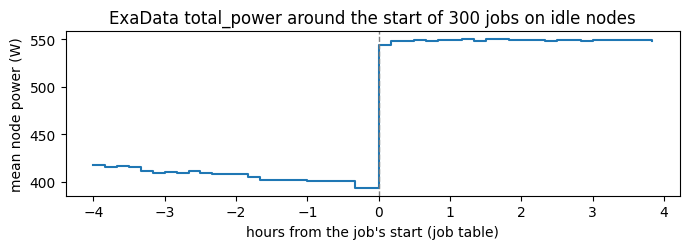

In [5]:
fig, ax = plt.subplots(figsize=(7, 2.6))
ax.step(bins[:-1] / 3600, profile, where="post", color="C0")
ax.axvline(0, color="gray", lw=1, ls="--")
ax.set_xlabel("hours from the job's start (job table)")
ax.set_ylabel("mean node power (W)")
ax.set_title("ExaData total_power around the start of 300 jobs on idle nodes")
plt.tight_layout()

## 3. PM100's own power traces are two hours late

For the 150 jobs whose PM100 trace varies, we correlate the first 720 samples (4 h) with the
ExaData `total_power` of the same node, with the trace shifted by −2 h to +2 h. Sample *k* of a
trace is compared with the ExaData reading nearest to start + shift + 20·*k* s (within 20 s).

In [6]:
shifts = [-7200, -3600, 0, 3600, 7200]
corr = {s: [] for s in shifts}
for r in varying.itertuples():
    p = np.asarray(trace[r.job_id][:720], float)
    ts, v = power[r.node]
    s0 = r.start_time.value // 10**6
    for s in shifts:
        grid = s0 + s * 1000 + np.arange(len(p)) * 20000
        i = np.clip(np.searchsorted(ts, grid), 0, len(ts) - 1)
        ok = np.abs(ts[i] - grid) <= 20000
        if ok.mean() < 0.8 or v[i][ok].std() == 0:
            continue
        corr[s].append(np.corrcoef(p[ok], v[i][ok])[0, 1])
median = {s / 3600: float(np.median(c)) for s, c in corr.items()}
print(pd.Series(median, name="median correlation").rename_axis("shift (h)").round(3).to_string())
claim("Median correlation, trace shifted +2 h", median[2.0], "0.83")
claim("Median correlation, no shift", median[0.0], "0.00", note="paper: 'about 0.00'")

shift (h)
-2.0   -0.059
-1.0   -0.039
 0.0   -0.001
 1.0    0.018
 2.0    0.835
OK    Median correlation, trace shifted +2 h: 0.83   (paper: 0.83)
OK    Median correlation, no shift: -0.00   (paper: 0.00)   [paper: 'about 0.00']


True

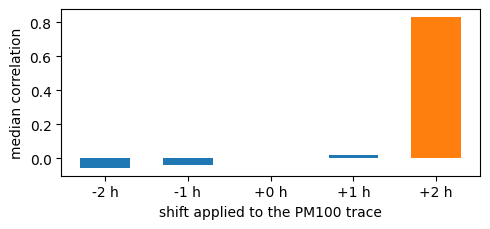

In [7]:
fig, ax = plt.subplots(figsize=(5, 2.4))
ax.bar([f"{h:+.0f} h" for h in median], list(median.values()), color=["C1" if h == 2 else "C0" for h in median], width=0.6)
ax.set_ylabel("median correlation")
ax.set_xlabel("shift applied to the PM100 trace")
plt.tight_layout()

Conclusion: ExaData telemetry and the job tables share one clock, so the window
`[start, start + 20 min)` really covers the first 20 minutes of the job. The PM100 traces are
offset by +2 h (consistent with a CEST/UTC confusion when PM100 was built); this study reads
power from ExaData only.

In [8]:
save_claims("03_clock")

7 claims checked, 0 differ from the paper -> results/claims/03_clock.csv


,claim,computed,paper,ok,note
0,PM100 jobs whose times agree with ExaData to t...,231238,"231,238",True,
1,Jobs in the power-step check,300,300,True,
2,Node power before the start (W),393,393,True,
3,Node power after the start (W),544,544,True,
4,Start of the bin with the largest step (h),0,0,True,
5,"Median correlation, trace shifted +2 h",0.83,0.83,True,
6,"Median correlation, no shift",-0.00,0.00,True,paper: 'about 0.00'
